Importing librairies

In [7]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
from sklearn.metrics import mean_squared_error
print(os.getcwd())

fontsize = 25

c:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe


Reading Datas

In [8]:
root = r'C:\Users\nberr\ENS_Lyon\Thèse\Experimental\Salle_particules_unique\Nanodisks\Sylvie\disque ar 2.3 sur SAPHIR\zone1\zone1-NDe\PaP 06 nov 2024_Pp-6uW_p410nm_s540nm'
files = os.listdir(root + r'\Traces')

Data_list = [{} for i in range(len(files))]

for i in range(len(files)) :

    lines = open( root + '/Traces/' +files[i],'r').readlines()

    #print(files[i])
    Data_list[i]["t_i"] = float(lines[2].strip())
    Data_list[i]["t_f"] = float(lines[3].strip())
    Data_list[i]["t_step"] = float(lines[4].strip())


    nb_t_values = int(lines[5].strip()) 

    Data_list[i]["t"] = []
    Data_list[i]["DTT"] = []

    for j in range(nb_t_values):
        a,b = lines[10+j].strip().split(',')
        Data_list[i]["t"].append(float(a))
        Data_list[i]["DTT"].append(float(b))

    Data_list[i]["DTT"]  = np.array(Data_list[i]["DTT"])
    Data_list[i]["t"]  = np.array(Data_list[i]["t"])

## Selection of scan to plot

### Select 1st and last scan

In [9]:
n_depart = 0
n_fin = len(files)


### Set the name of Output

Les fichiers sont nommés ainsi : "fmmjjss_Scan_k.dat"

mm : le mois

jj : le jour

ss : le numéro de la série (on change de numéro de série dès qu'on réaligne)

k : le numéro de scan pour la série en cours

In [10]:
scan_name = files[n_depart][1:7]


if files[n_depart+n_fin-1][5:7]!=files[n_depart][5:7]:  # several series of traces
    scan_name+='-'+files[n_depart+n_fin-1][5:7]
        
files_str = scan_name +' pp417 pr835 pol60' #Name of output file
column_str = 'grid4 ND4-9 (10.03) 12.0uW' #str data within the file

## Plot des scans sélectionnés

Text(0, 0.5, 'DT/t (1e-5)')

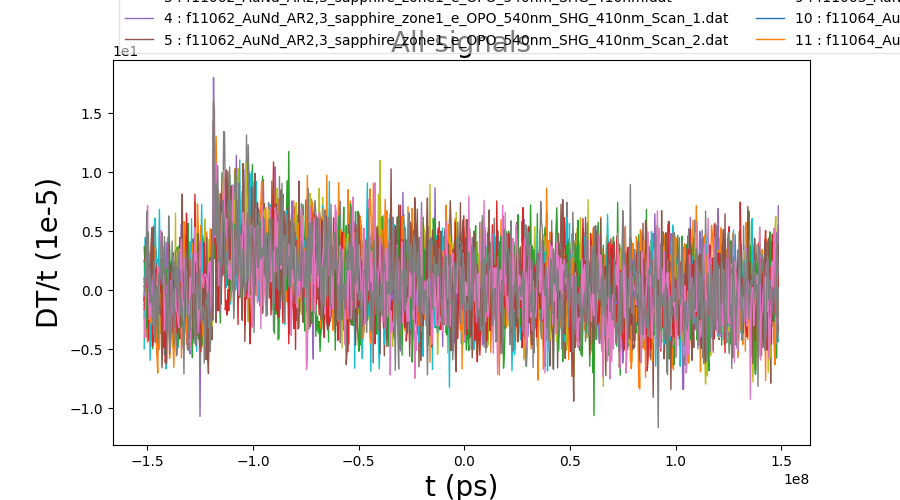

In [11]:
offset = 0.0000 #global offset to give to each signal for plot

fig = plt.figure(figsize = (9,5))
for i in range(n_depart,n_depart+n_fin):
    plt.plot(Data_list[i]["t"]*1e5,Data_list[i]["DTT"]*1e5-i*offset,
             label=str(i)+' : '+files[i], linewidth=1)
    plt.legend(framealpha=0.5,loc='lower left', bbox_to_anchor=(0, 1),ncol=3)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
#plt.ylim(0,1.2e-4)
#plt.xlim(-1420,-1380)

plt.title('All signals', fontsize= 20)
plt.xlabel('t (ps)', fontsize=20)
plt.ylabel('DT/t (1e-5)', fontsize=20)

## Averaging all traces

### Synchronize all times for every scan

In [12]:
def synchronize(Data_list, n_depart, n_fin) :
    
    e = {Data_list[n_depart+i]['t_step'] for i in range(n_fin-n_depart)} 

    if len(e)==1:
        dt = Data_list[n_depart]['t_step']
    else:
        dt = 1
        raise ValueError('The time steps are different between time traces')

    t_min = np.min([Data_list[n_depart+k]['t_i'] for k in range(n_fin - n_depart)])
    t_max = np.max([Data_list[n_depart+k]['t_f'] for k in range(n_fin - n_depart)])

    n = int((t_max-t_min)/dt) +1

    t_sync = np.linspace(t_min, t_max, n)

    DTT_sync_all = [[] for i in range(n)]

    for i in range(n_depart, n_depart+n_fin) :
        t = Data_list[i]['t']
        DTT = Data_list[i]['DTT']
        
        
        for j in range(len(t)) :
            
            t_index = np.searchsorted(t_sync, t[j])
            DTT_sync_all[t_index].append(DTT[j])


    DTT_sync = np.array([np.mean(DTT_sync_all[k]) for k in range(len(DTT_sync_all))])

    return(t_sync, DTT_sync, dt)


In [13]:
t_sync, DTT_sync, dt = synchronize(Data_list, n_depart, n_fin)

## Data treatement

### Find the zero delay

In [14]:
# electron peak postion:
#n_0 = 0

n_0 = int(np.where(np.abs(DTT_sync)==max(np.abs(DTT_sync)))[0])

time_zero=t_sync[n_0]
delay_tot = t_sync - t_sync[n_0]


C:\Users\nberr\AppData\Local\Temp\ipykernel_6792\4122262272.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  n_0 = int(np.where(np.abs(DTT_sync)==max(np.abs(DTT_sync)))[0])


### Get the mean value before excitation

In [15]:
idx_start = 4 #index to start the mean
idx_end = n_0 - 3 #index to end the mean

mean_start = np.average(DTT_sync[idx_start:idx_end])

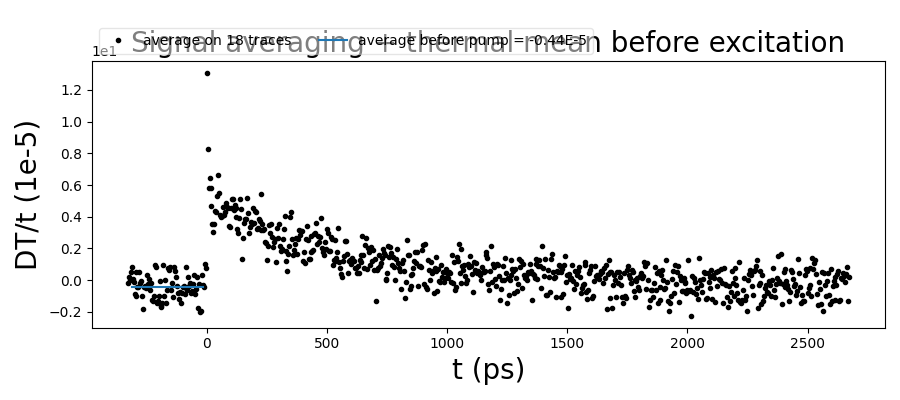

In [16]:
fig = plt.figure(figsize = (9,4))
ax = fig.add_subplot(1, 1, 1)
for i in range(n_depart,n_depart+n_fin):
    #plt.plot(delay_tot,np.array(Data_list[i]["DTT"]),
    #         label=str(i)+' : '+files[i])
    pass
    

plt.plot(delay_tot,DTT_sync*1e5,'k.',
         label='average on {} traces'.format(n_fin-n_depart))

plt.plot(delay_tot[idx_start:idx_end], [mean_start*1e5]*(idx_end-idx_start), 
         label='average before pump = {}E-5'.format(round(1e5*mean_start,2)))

rect = plt.Rectangle((delay_tot[0],0), delay_tot[-1]-delay_tot[0], mean_start, 
                 color='r', linewidth=0, alpha=0.3)
ax.add_patch(rect)
plt.legend(framealpha=0.5,loc='lower left', bbox_to_anchor=(0, 1),ncol=3)
#plt.ylim(1e-3,2e-3)
#plt.xlim(delay_tot[0],delay_tot[n_0+2])
#plt.xlim(-10,300)

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
plt.title('Signal averaging + thermal mean before excitation', fontsize= 20)
plt.xlabel('t (ps)', fontsize=20)
plt.ylabel('DT/t (1e-5)', fontsize=20)
plt.tight_layout()





Text(0, 0.5, 'DT/t (1e-5)')

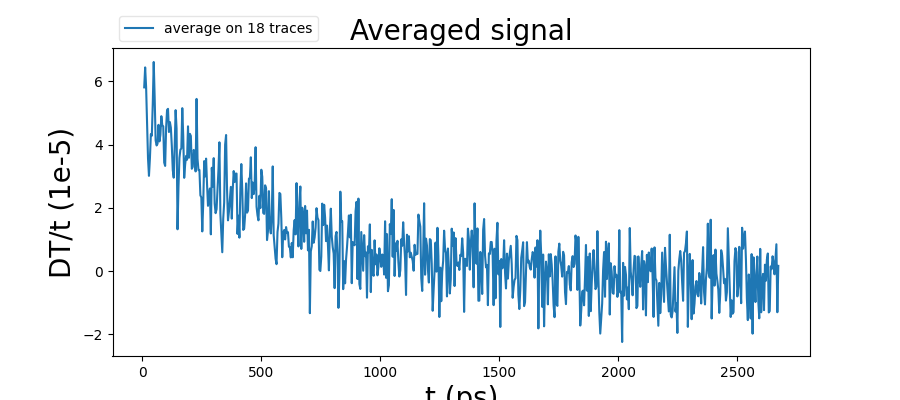

In [17]:
n_start = n_0+2 # first value of the series to be plotted

delay = delay_tot[n_start:]
#signal = DTT_sync - mean_start
signal = DTT_sync[n_start:]   #MEAN START KEPT
#signal = DTT_sync - min(DTT_sync) #if signal becomes negative at some point -> add offset

fig = plt.figure(figsize = (9,4))
#for i in range(k,k+nb_to_show):
#    plt.plot(delay,np.array(DTT_axes_list[i])[n_start:],
#             label=str(i)+' : '+files[i])
plt.plot(delay,signal*1e5,'-', label='average on {} traces'.format(n_fin-n_depart))

#plt.scatter(delay,signal*1e5,c='r', label='average on {} traces'.format(n_fin-n_depart))

plt.legend(framealpha=0.5,loc='lower left', bbox_to_anchor=(0, 1),ncol=3)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
#plt.xlim(350,1000) #to zoom

plt.title('Averaged signal', fontsize= 20)
plt.xlabel('t (ps)', fontsize=20)
plt.ylabel('DT/t (1e-5)', fontsize=20)


### Make the signal TF

make TF

In [18]:
sp = np.fft.rfft(signal)

freq = 1000*np.fft.rfftfreq(len(delay),dt)  #frequency in GHz
df = freq[1]-freq[0]


sp_amp = np.absolute(sp)
sp_phase = np.angle(sp)

Finding peaks corresponding in oscillating modes

In [19]:

peaks, peak_dic = find_peaks(sp_amp, height=1e-3, threshold=0.8e-3)

width, width_height, left, right = peak_widths(sp_amp, peaks, rel_height=0.5 )


try :
    width = np.array(width)*df
    i_peak = peaks[0]
    print(peaks)
    print(width)

except :
    pass

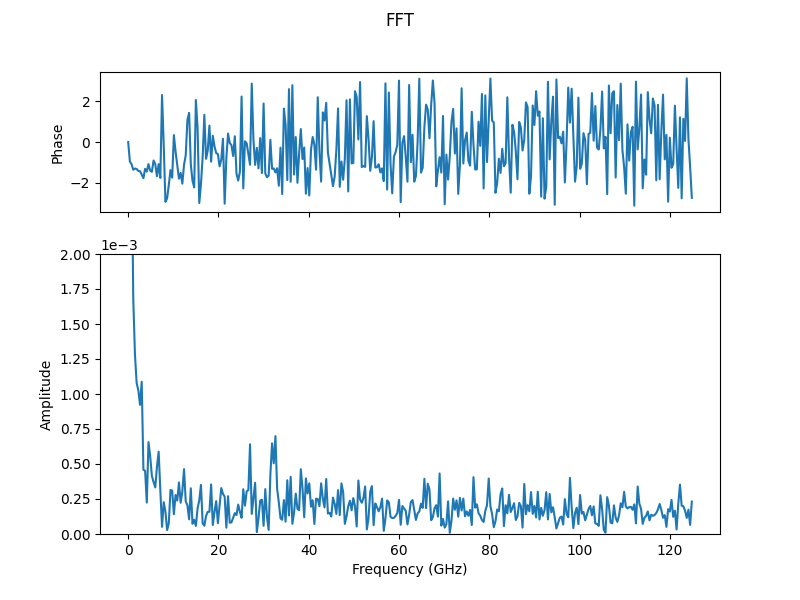

In [20]:
f, (a0, a1) = plt.subplots(2,1, figsize=(8,6), sharex=True,
    gridspec_kw = {'height_ratios':[1, 2]})
a0.plot(freq, sp_phase)
f.suptitle('FFT')
a0.set_ylabel('Phase')

a1.plot(freq, sp_amp)

try :
        
    for j in range(len(peaks)):
        i = peaks[j]
        
        a1.text(freq[i], sp_amp[i]+0.02*sp_amp[0],
                "{0:.2f}".format(1000/freq[i]),horizontalalignment='center',
                verticalalignment='bottom')
        
        f_left = freq[int(left[j])]+df*np.mod(left[j], 1)
        f_right = freq[int(right[j])]+df*np.mod(right[j], 1)
        whm = sp_amp[i]/2

        a1.scatter(f_left, whm, c='r')
        a1.scatter(f_right, whm, c='r')

except :
    pass

a1.set_ylim(0,0.2e-2)
#a1.set_xlim(0,50)
a1.set_xlabel('Frequency (GHz)')
a1.set_ylabel('Amplitude')
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

In [21]:
def cut_f(signal, delay, f_cut) :
    """from a temporal signal, create 2 temporal signal with a cut respectively above and below f_cut in their spectral domain.

    Args:
        signal (1D array): the signal
        delay (1D array): the time delay of the signal in ps
        f_cut (float): the frequency of cutting in GHz
    """
    
    dt = delay[1]-delay[0]
    freq = 1000*np.fft.rfftfreq(len(delay),dt)
    signal_tf = np.fft.rfft(signal)
    idx_f_cut = np.searchsorted(freq, f_cut, side='left')

    tf_cut_high_f = signal_tf.copy()
    tf_cut_high_f[idx_f_cut:] = 0

    tf_cut_low_f = signal_tf.copy()
    tf_cut_low_f[:idx_f_cut] = 0

    signal_cut_high_f = np.fft.irfft(tf_cut_high_f, n=np.size(delay))
    signal_cut_low_f = np.fft.irfft(tf_cut_low_f, n=np.size(delay))



    return(signal_cut_high_f, signal_cut_low_f)


In [22]:
f_cut = 45
signal_noise_removed, _ = cut_f(signal, delay, f_cut)

f_cut_2 = 21

signal_osc_removed, signal_exp_removed = cut_f(signal, delay, f_cut_2)

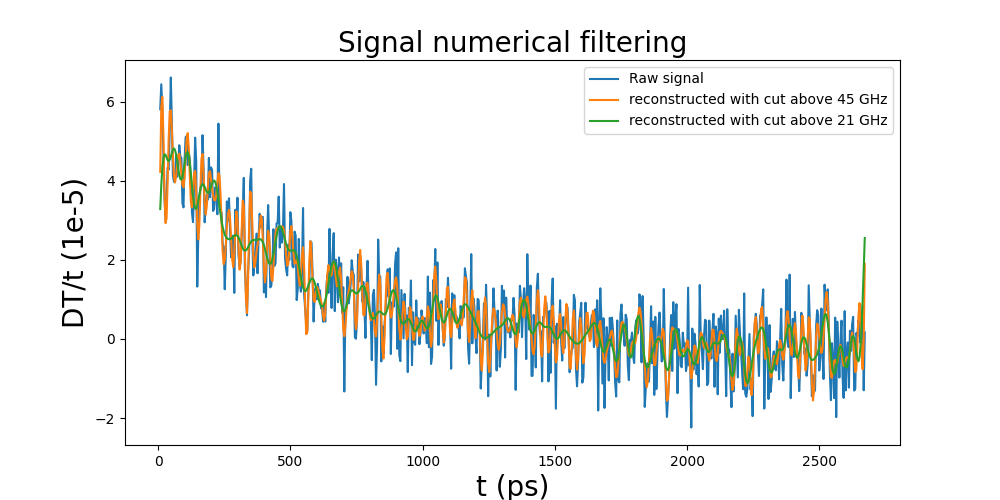

In [23]:
fig = plt.figure(figsize=(10,5))
plt.plot(delay, signal*1e5, label = 'Raw signal')
plt.plot(delay, signal_noise_removed*1e5, label = 'reconstructed with cut above {} GHz'.format(f_cut))
plt.plot(delay, signal_osc_removed*1e5, label = 'reconstructed with cut above {} GHz'.format(f_cut_2))

plt.title('Signal numerical filtering', fontsize= 20)
plt.xlabel('t (ps)', fontsize=20)
plt.ylabel('DT/t (1e-5)', fontsize=20)
plt.legend()

## Fitting Data
### Thermal part

In [24]:
def ExpDec4(x,A1,t1,A2,t2,A3,t3,A4,t4):
    return  mean_start+A1*np.exp(-x/t1) + A2*np.exp(-x/t2)+ A3*np.exp(-x/t3) + A4*np.exp(-x/t4)
def ExpDec3(x,A1,t1,A2,t2,A3,t3):
    return  mean_start+A1*np.exp(-x/t1) + A2*np.exp(-x/t2)+ A3*np.exp(-x/t3)
def ExpDec2(x,A1,t1,A2,t2):
    return  mean_start+A1*np.exp(-x/t1) + A2*np.exp(-x/t2)
def ExpDec1(t,A1,t1):
    return  mean_start+A1*np.exp(-t/t1)

In [25]:
def fit_signal_exp(signal_to_fit, delay, p01, p02, p03, p04, Bounds_low, Bounds_high) :
    """make the exponential fit for the function

    Args:
        signal_to_fit (1D array): signal
        delay (1D array): time
        p01 (tuple): fitting parameter for the 1 exp fit
        p02 (tuple): fitting parameter for the 2 exp fit
        p03 (tuple): fitting parameter for the 3 exp fit
        p04 (tuple): fitting parameter for the 4 exp fit
        Bounds_low (list): list of the 6 bounds
        Bounds_high (list): list of the 6 bounds

    Returns:
        resi (tuple): each res is a tuple (popt, pcov, err)
    """

    # Curve fitting
    popt1, pcov1 = curve_fit(ExpDec1, delay, signal_to_fit, p0=p01)
    popt2, pcov2 = curve_fit(ExpDec2, delay, signal_to_fit, p0=p02, bounds=(Bounds_low[0:4], Bounds_high[0:4]))                         
    popt3, pcov3 = curve_fit(ExpDec3, delay, signal_to_fit, p0=p03, bounds=(Bounds_low[0:6], Bounds_high[0:6]))
    popt4, pcov4 = curve_fit(ExpDec4, delay, signal_to_fit, p0=p04, bounds=(Bounds_low, Bounds_high))


    # Residual errors
    err_1 = mean_squared_error(signal_to_fit,ExpDec1(delay,*popt1))/np.abs(np.max(signal_to_fit))
    err_2 = mean_squared_error(signal_to_fit,ExpDec2(delay,*popt2))/np.abs(np.max(signal_to_fit))
    err_3 = mean_squared_error(signal_to_fit,ExpDec3(delay,*popt3))/np.abs(np.max(signal_to_fit))
    err_4 = mean_squared_error(signal_to_fit,ExpDec4(delay,*popt4))/np.abs(np.max(signal_to_fit))

    res1 = (popt1, pcov1, err_1)
    res2 = (popt2, pcov2, err_2)
    res3 = (popt3, pcov3, err_3)
    res4 = (popt4, pcov4, err_4)


    return (res1, res2, res3, res4)
    

In [26]:
# Set the signal we're gonna fit
signe_pic = 1



p01 = signe_pic*2.e-4, 100
p02 = signe_pic*2.e-5, 55., signe_pic*2.e-5, 100.
p03 = signe_pic*2.e-5,  55., signe_pic*2.e-5, 100., signe_pic*2.e-5, 800.
p04 = signe_pic*2.e-5,  55., signe_pic*2.e-5, 100., signe_pic*2.e-5, 800., signe_pic*2e-5, 3200.


if signe_pic == -1 :
    Bounds_low =  [-np.inf, 40, -np.inf, 100, -np.inf, 400, -np.inf, 1500]
    Bounds_high = [0,np.inf,0,np.inf,0,np.inf, 0, np.inf]

else :
    Bounds_low =  [0, 40, 0, 100, 0, 400, 0, 1500]
    Bounds_high = [np.inf,np.inf,np.inf,np.inf,np.inf,np.inf, np.inf, np.inf]


#fit the raw signal
res1, res2, res3, res4 = fit_signal_exp(signal, delay, p01, p02, p03, p04, Bounds_low, Bounds_high)
popt1, pcov1, err_1 = res1
popt2, pcov2, err_2 = res2
popt3, pcov3, err_3 = res3
popt4, pcov4, err_4 = res4

#fit the treated signal
res1_noise, res2_noise, res3_noise, res4_noise = fit_signal_exp(signal_noise_removed, delay, p01, p02, p03, p04, Bounds_low, Bounds_high)
popt1_noise, pcov1_noise, err_1_noise = res1_noise
popt2_noise, pcov2_noise, err_2_noise = res2_noise
popt3_noise, pcov3_noise, err_3_noise = res3_noise


#fit the treated signal
res1_osc, res2_osc, res3_osc, res4_osc = fit_signal_exp(signal_osc_removed, delay, p01, p02, p03, p04, Bounds_low, Bounds_high)
popt1_osc, pcov1_osc, err_1_osc = res1_osc
popt2_osc, pcov2_osc, err_2_osc = res2_osc
popt3_osc, pcov3_osc, err_3_osc = res3_osc


C:\Users\nberr\AppData\Local\Temp\ipykernel_6792\1327351270.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


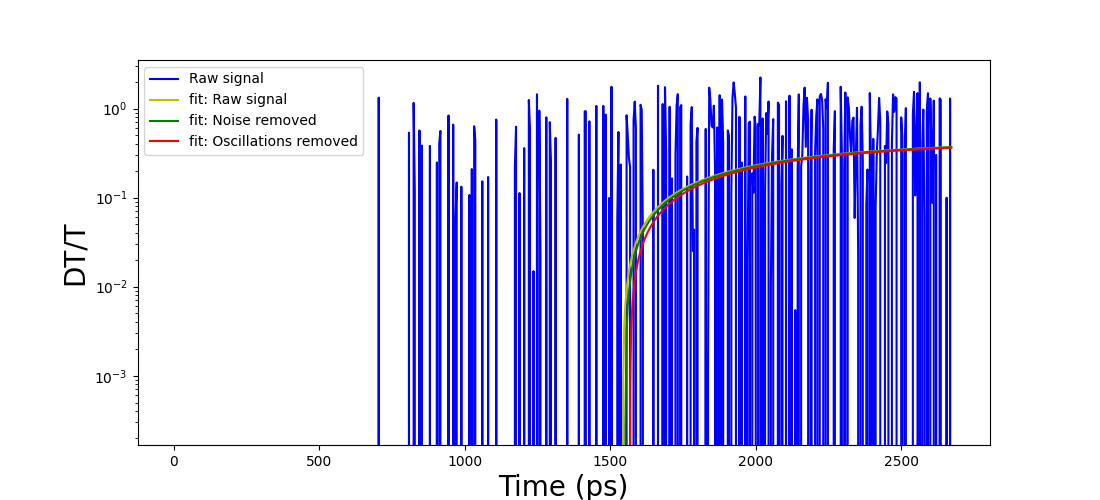

In [27]:
offset = 5

fig = plt.figure(figsize = (11,5))
#Choose which fits to plot
plt.semilogy(delay, -signal*1e5, label='Raw signal', c='blue')
plt.semilogy(delay, -ExpDec1(delay,*popt1)*1e5, 'y-',label='fit: Raw signal')
plt.semilogy(delay, -ExpDec1(delay,*popt1_noise)*1e5, 'g-',label='fit: Noise removed')
plt.semilogy(delay, -ExpDec1(delay,*popt1_osc)*1e5, 'r-',label='fit: Oscillations removed')

plt.text(delay[-30], signal[-5]*1e5-offset*0.2, '1 exponential')

plt.xlabel('Time (ps)', fontsize=20)
plt.ylabel('DT/T', fontsize=20)




plt.legend()
plt.tight_layout()




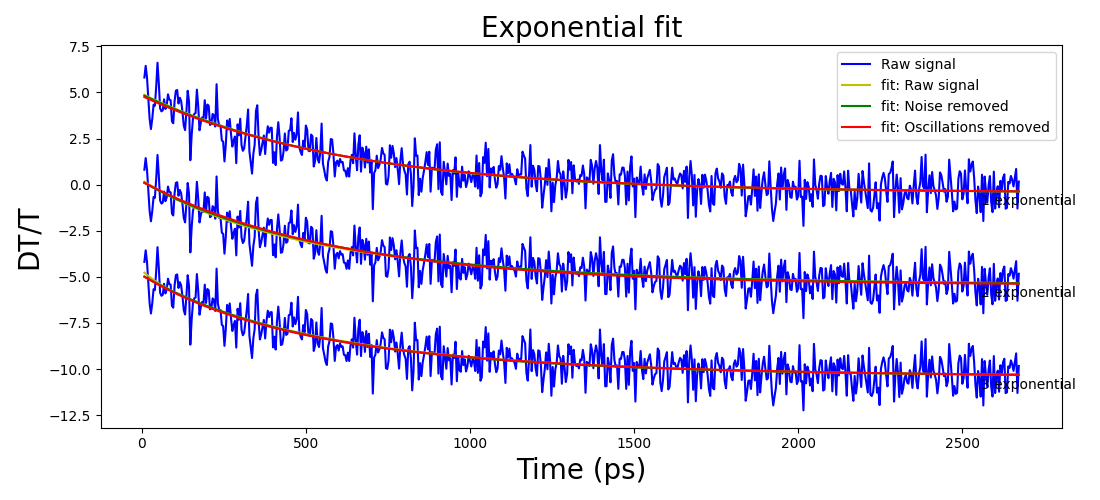

In [28]:
offset = 5

fig = plt.figure(figsize = (11,5))
#Choose which fits to plot
plt.plot(delay, signal*1e5, label='Raw signal', c='blue')
plt.plot(delay, ExpDec1(delay,*popt1)*1e5, 'y-',label='fit: Raw signal')
plt.plot(delay, ExpDec1(delay,*popt1_noise)*1e5, 'g-',label='fit: Noise removed')
plt.plot(delay, ExpDec1(delay,*popt1_osc)*1e5, 'r-',label='fit: Oscillations removed')

plt.text(delay[-30], signal[-5]*1e5-offset*0.2, '1 exponential')

plt.xlabel('Time (ps)', fontsize=20)
plt.ylabel('DT/T', fontsize=20)


plt.plot(delay, signal*1e5-offset,c='blue')
plt.plot(delay, ExpDec2(delay,*popt2)*1e5-offset, 'y-')
plt.plot(delay, ExpDec2(delay,*popt2_noise)*1e5-offset, 'g-')
plt.plot(delay, ExpDec2(delay,*popt2_osc)*1e5-offset, 'r-')
plt.text(delay[-30], signal[-5]*1e5-offset*1.2, '2 exponential')



plt.plot(delay, signal*1e5-2*offset, c='blue')
plt.plot(delay, ExpDec3(delay,*popt3)*1e5-2*offset, 'y-')
plt.plot(delay, ExpDec3(delay,*popt3_noise)*1e5-2*offset, 'g-')
plt.plot(delay, ExpDec3(delay,*popt3_osc)*1e5-2*offset, 'r-')
plt.text(delay[-30], signal[-5]*1e5-offset*2.2, '3 exponential')


plt.title(r'Exponential fit', fontsize=20)


plt.legend()
plt.tight_layout()




Remove the thermal part to the signal

In [29]:
n_exp_mode = 2


if n_exp_mode == 1 :
    thermal_fit = ExpDec3(delay,*popt3)
    thermal_fit_noise = ExpDec3(delay,*popt3_noise)
    thermal_fit_osc = ExpDec3(delay,*popt3_osc)

if n_exp_mode == 2 :
    thermal_fit = ExpDec2(delay,*popt2)
    thermal_fit_noise = ExpDec2(delay,*popt2_noise)
    thermal_fit_osc = ExpDec2(delay,*popt2_osc)

if n_exp_mode == 3 : 
    thermal_fit = ExpDec3(delay,*popt3)
    thermal_fit_noise = ExpDec3(delay,*popt3_noise)
    thermal_fit_osc = ExpDec3(delay,*popt3_osc)


vibrational = signal-thermal_fit
vibrational_noise = signal_noise_removed-thermal_fit_noise
vibrational_osc = signal-thermal_fit_osc

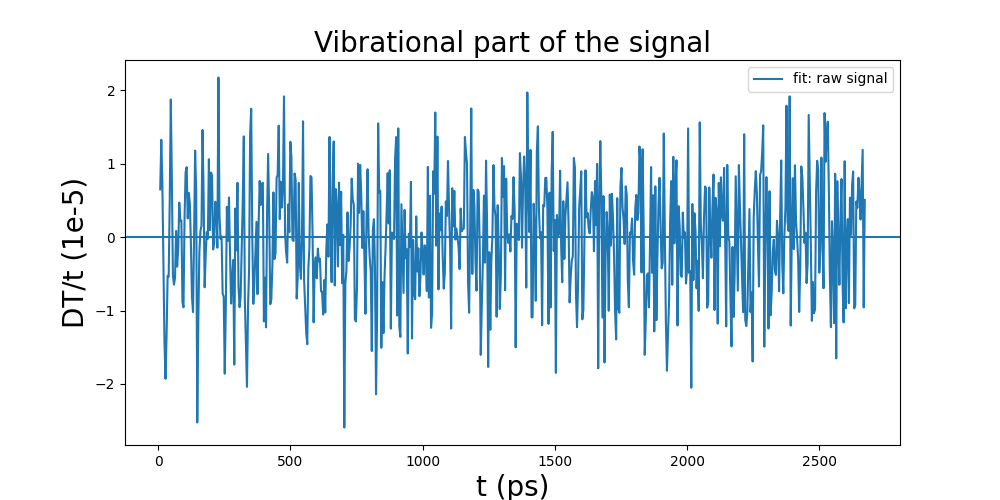

In [30]:
fig = plt.figure(figsize = (10, 5))

#plt.plot(delay, signal_exp_removed*1e5, label = 'Fourier filtered')
plt.plot(delay, vibrational*1e5, label='fit: raw signal')
#plt.plot(delay, vibrational_osc*1e5, label = 'fit : osc removed')
#plt.plot(delay, vibrational_noise*1e5, label = 'fit: noise removed')

plt.title('Vibrational part of the signal', fontsize=20)
plt.axhline(0)
plt.xlabel('t (ps)', fontsize=20)
plt.ylabel('DT/t (1e-5)', fontsize=20)
plt.legend()

In [31]:
def Osc4(t,mean, A1,tau1, T1, phi1,A2,tau2, T2, phi2,A3,tau3, T3, phi3,A4,tau4, T4, phi4):
    return  mean + A1*np.exp(-t/tau1)*np.sin(2*np.pi/T1*t+phi1) + \
            A2*np.exp(-t/tau2)*np.sin(2*np.pi/T2*t+phi2) + \
            A3*np.exp(-t/tau3)*np.sin(2*np.pi/T3*t+phi3) + \
            A4*np.exp(-t/tau4)*np.sin(2*np.pi/T4*t+phi4) 
def Osc3(t,mean, A1,tau1, T1, phi1,A2,tau2, T2, phi2,A3,tau3, T3, phi3):
    return  mean + A1*np.exp(-t/tau1)*np.sin(2*np.pi/T1*t+phi1) + \
            A2*np.exp(-t/tau2)*np.sin(2*np.pi/T2*t+phi2) + \
            A3*np.exp(-t/tau3)*np.sin(2*np.pi/T3*t+phi3)
def Osc2(t,mean, A1,tau1, T1, phi1,A2,tau2, T2, phi2):
    return  mean + A1*np.exp(-t/tau1)*np.sin(2*np.pi/T1*t+phi1) + \
            A2*np.exp(-t/tau2)*np.sin(2*np.pi/T2*t+phi2)
def Osc1(t,mean, A1,tau1, T1, phi1):
    return  mean + A1*np.exp(-t/tau1)*np.sin(2*np.pi/T1*t+phi1)

In [32]:
def fit_signal_osc(signal_to_fit, delay, p01, p02, p03, p04, Bounds_low, Bounds_high) :
    """make the exponential fit for the function

    Args:
        signal_to_fit (1D array): signal
        delay (1D array): time
        p01 (tuple): fitting parameter for the 1 exp fit
        p02 (tuple): fitting parameter for the 2 exp fit
        p03 (tuple): fitting parameter for the 3 exp fit
        p04 (tuple): fitting parameter for the 4 exp fit
        Bounds_low (list): list of the 6 bounds
        Bounds_high (list): list of the 6 bounds

    Returns:
        resi (tuple): each res is a tuple (popt, pcov, err)
    """

    # Curve fitting
    popt1, pcov1 = curve_fit(Osc1, delay, signal_to_fit, p0=p01)
    popt2, pcov2 = curve_fit(Osc2, delay, signal_to_fit, p0=p02, bounds=(Bounds_low[0:9], Bounds_high[0:9]))                         
    popt3, pcov3 = curve_fit(Osc3, delay, signal_to_fit, p0=p03, bounds=(Bounds_low[0:13], Bounds_high[0:13]))
    popt4, pcov4 = curve_fit(Osc4, delay, signal_to_fit, p0=p04, bounds=(Bounds_low, Bounds_high))


    # Residual errors
    err_1 = mean_squared_error(signal_to_fit,Osc1(delay,*popt1))/np.abs(np.max(signal_to_fit))
    err_2 = mean_squared_error(signal_to_fit,Osc2(delay,*popt2))/np.abs(np.max(signal_to_fit))
    err_3 = mean_squared_error(signal_to_fit,Osc3(delay,*popt3))/np.abs(np.max(signal_to_fit))
    err_4 = mean_squared_error(signal_to_fit,Osc4(delay,*popt4))/np.abs(np.max(signal_to_fit))

    res1 = (popt1, pcov1, err_1)
    res2 = (popt2, pcov2, err_2)
    res3 = (popt3, pcov3, err_3)
    res4 = (popt4, pcov4, err_4)

    return (res1, res2, res3, res4)
    


In [33]:
# Set the signal we're gonna fit
# p01 = mean, A, tau, T, phi
p01 = 0, 2e-5, 200, 30, 0
p02 = 0, 2e-5, 200, 30, 0, 0.1e-5, 100, 30, 0
p03 = 0 ,1e-5, 100, 30, 0, 0.1e-5, 100, 30, 0, 0.5e-5, 100, 30, 0
p04 = 0, 1e-5, 100, 30, 0, 0.1e-5, 100, 30, 0, 0.5e-5, 100, 30, 0, 0.5e-5, 100, 30, 0

Bounds_low = [-np.inf, 0, 0, 0, -np.pi, 0, 0, 0, -np.pi, 0, 0, 0, -np.pi, 0, 0, 0, -np.pi]
Bounds_high= [np.inf,np.inf,np.inf,np.inf,np.pi,np.inf, np.inf, np.inf, np.pi,np.inf,np.inf,np.inf,np.pi,np.inf, np.inf, np.inf, np.pi]


In [34]:


#fit the raw signal
res1, res2, res3, res4 = fit_signal_osc(vibrational, delay, p01, p02, p03, p04, Bounds_low, Bounds_high)
popt1, pcov1, err_1 = res1
popt2, pcov2, err_2 = res2
popt3, pcov3, err_3 = res3
popt4, pcov4, err_4 = res4

#fit the treated signal
res1_noise, res2_noise, res3_noise, res4_noise = fit_signal_osc(vibrational_noise, delay, p01, p02, p03, p04, Bounds_low, Bounds_high)
popt1_noise, pcov1_noise, err_1_noise = res1_noise
popt2_noise, pcov2_noise, err_2_noise = res2_noise
popt3_noise, pcov3_noise, err_3_noise = res3_noise

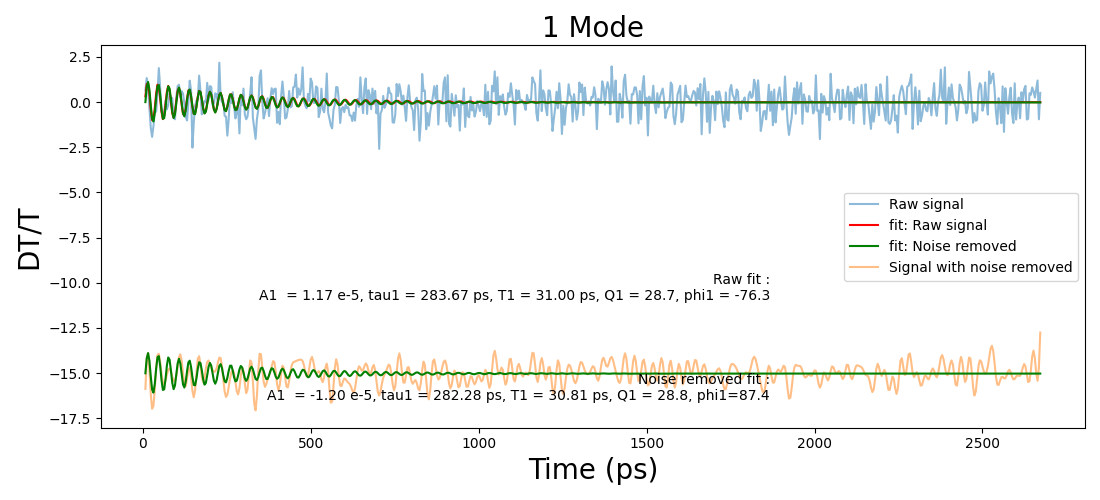

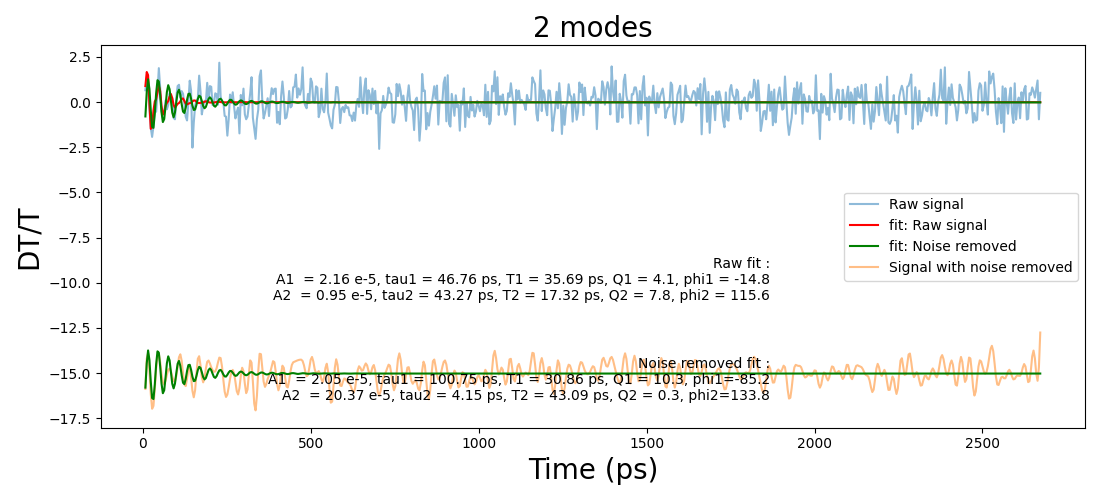

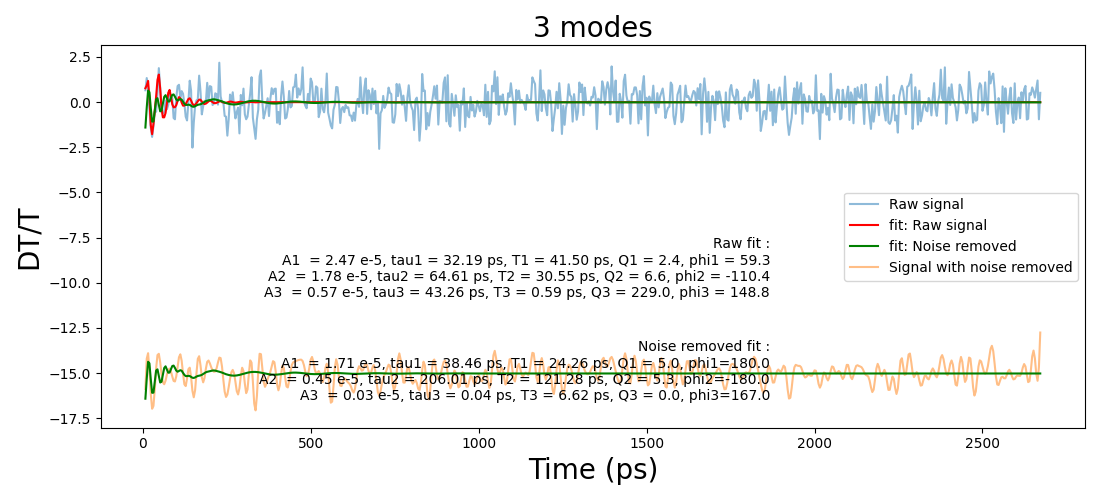

In [35]:
alpha=0.5
offset = 15


fig = plt.figure(figsize = (11,5))
ax = plt.gca()
#Choose which fits to plot
plt.plot(delay, vibrational*1e5, label='Raw signal', alpha=alpha)
plt.plot(delay, Osc1(delay,*popt1)*1e5, 'r-',label='fit: Raw signal')
plt.plot(delay, Osc1(delay,*popt1_noise)*1e5, 'g-',label='fit: Noise removed')


plt.plot(delay, vibrational_noise*1e5-offset, label='Signal with noise removed', alpha=alpha)
plt.plot(delay, Osc1(delay,*popt1_noise)*1e5-offset, 'g-')

plt.title(r'1 Mode', fontsize=20)

plt.xlabel('Time (ps)', fontsize=20)
plt.ylabel('DT/T', fontsize=20)



text_raw = 'Raw fit :' + '\n' + 'A1  = {:.2f} e-5, tau1 = {:.2f} ps, T1 = {:.2f} ps, Q1 = {:.1f}, phi1 = {:.1f}'.format(popt1[1]*1e5, popt1[2], popt1[3], np.pi*popt1[2]/popt1[3], popt1[4]*180/np.pi)
text_noise = 'Noise removed fit :' + '\n' + 'A1  = {:.2f} e-5, tau1 = {:.2f} ps, T1 = {:.2f} ps, Q1 = {:.1f}, phi1={:.1f}'.format(popt1_noise[1]*1e5, popt1_noise[2], popt1_noise[3], np.pi*popt1_noise[2]/popt1_noise[3], popt1_noise[4]*180/np.pi) 
plt.text(0.7, 0.4, text_raw, horizontalalignment = 'right', transform=plt.gcf().transFigure)
plt.text(0.7, 0.2, text_noise, horizontalalignment = 'right', transform=plt.gcf().transFigure)
plt.legend()
plt.tight_layout()



fig = plt.figure(figsize = (11,5))
ax = plt.gca()
#Choose which fits to plot
plt.plot(delay, vibrational*1e5, label='Raw signal', alpha=alpha)
plt.plot(delay, Osc2(delay,*popt2)*1e5, 'r-',label='fit: Raw signal')
plt.plot(delay, Osc2(delay,*popt2_noise)*1e5, 'g-',label='fit: Noise removed')


plt.plot(delay, vibrational_noise*1e5-offset, label='Signal with noise removed', alpha=alpha)
plt.plot(delay, Osc2(delay,*popt2_noise)*1e5-offset, 'g-')

plt.title(r'2 modes', fontsize=20)

plt.xlabel('Time (ps)', fontsize=20)
plt.ylabel('DT/T', fontsize=20)


text_raw = 'Raw fit :' + '\n' + 'A1  = {:.2f} e-5, tau1 = {:.2f} ps, T1 = {:.2f} ps, Q1 = {:.1f}, phi1 = {:.1f}'.format(popt2[1]*1e5, popt2[2], popt2[3], np.pi*popt2[2]/popt2[3], popt2[4]*180/np.pi) \
                       + '\n' + 'A2  = {:.2f} e-5, tau2 = {:.2f} ps, T2 = {:.2f} ps, Q2 = {:.1f}, phi2 = {:.1f}'.format(popt2[5]*1e5, popt2[6], popt2[7], np.pi*popt2[6]/popt2[7], popt2[8]*180/np.pi)
text_noise = 'Noise removed fit :' + '\n' + 'A1  = {:.2f} e-5, tau1 = {:.2f} ps, T1 = {:.2f} ps, Q1 = {:.1f}, phi1={:.1f}'.format(popt2_noise[1]*1e5, popt2_noise[2], popt2_noise[3], np.pi*popt2_noise[2]/popt2_noise[3], popt2_noise[4]*180/np.pi) \
                                   + '\n' + 'A2  = {:.2f} e-5, tau2 = {:.2f} ps, T2 = {:.2f} ps, Q2 = {:.1f}, phi2={:.1f}'.format(popt2_noise[5]*1e5, popt2_noise[6], popt2_noise[7], np.pi*popt2_noise[6]/popt2_noise[7], popt2_noise[8]*180/np.pi)

plt.text(0.7, 0.4, text_raw, horizontalalignment = 'right', transform=plt.gcf().transFigure)
plt.text(0.7, 0.2, text_noise, horizontalalignment = 'right', transform=plt.gcf().transFigure)
plt.legend()
plt.tight_layout()


fig = plt.figure(figsize = (11,5))
ax = plt.gca()
#Choose which fits to plot
plt.plot(delay, vibrational*1e5, label='Raw signal', alpha=alpha)
plt.plot(delay, Osc3(delay,*popt3)*1e5, 'r-',label='fit: Raw signal')
plt.plot(delay, Osc3(delay,*popt3_noise)*1e5, 'g-',label='fit: Noise removed')


plt.plot(delay, vibrational_noise*1e5-offset, label='Signal with noise removed', alpha=alpha)
plt.plot(delay, Osc3(delay,*popt3_noise)*1e5-offset, 'g-')

plt.title(r'3 modes', fontsize=20)

plt.xlabel('Time (ps)', fontsize=20)
plt.ylabel('DT/T', fontsize=20)

text_raw = 'Raw fit :' + '\n' + 'A1  = {:.2f} e-5, tau1 = {:.2f} ps, T1 = {:.2f} ps, Q1 = {:.1f}, phi1 = {:.1f}'.format(popt3[1]*1e5, popt3[2], popt3[3], np.pi*popt3[2]/popt3[3], popt3[4]*180/np.pi) \
                       + '\n' + 'A2  = {:.2f} e-5, tau2 = {:.2f} ps, T2 = {:.2f} ps, Q2 = {:.1f}, phi2 = {:.1f}'.format(popt3[5]*1e5, popt3[6], popt3[7], np.pi*popt3[6]/popt3[7], popt3[8]*180/np.pi) \
                       + '\n' + 'A3  = {:.2f} e-5, tau3 = {:.2f} ps, T3 = {:.2f} ps, Q3 = {:.1f}, phi3 = {:.1f}'.format(popt3[9]*1e5, popt3[10], popt3[11], np.pi*popt3[10]/popt3[11], popt3[12]*180/np.pi)
text_noise = 'Noise removed fit :' + '\n' + 'A1  = {:.2f} e-5, tau1 = {:.2f} ps, T1 = {:.2f} ps, Q1 = {:.1f}, phi1={:.1f}'.format(popt3_noise[1]*1e5, popt3_noise[2], popt3_noise[3], np.pi*popt3_noise[2]/popt3_noise[3], popt3_noise[4]*180/np.pi) \
                                   + '\n' + 'A2  = {:.2f} e-5, tau2 = {:.2f} ps, T2 = {:.2f} ps, Q2 = {:.1f}, phi2={:.1f}'.format(popt3_noise[5]*1e5, popt3_noise[6], popt3_noise[7], np.pi*popt3_noise[6]/popt3_noise[7], popt3_noise[8]*180/np.pi) \
                                   + '\n' + 'A3  = {:.2f} e-5, tau3 = {:.2f} ps, T3 = {:.2f} ps, Q3 = {:.1f}, phi3={:.1f}'.format(popt3_noise[9]*1e5, popt3_noise[10], popt3_noise[11], np.pi*popt3_noise[10]/popt3_noise[11], popt3_noise[12]*180/np.pi)
plt.text(0.7, 0.4, text_raw, horizontalalignment = 'right', verticalalignment='bottom', transform=plt.gcf().transFigure)
plt.text(0.7, 0.2, text_noise, horizontalalignment = 'right', transform=plt.gcf().transFigure)
plt.legend()
plt.tight_layout()


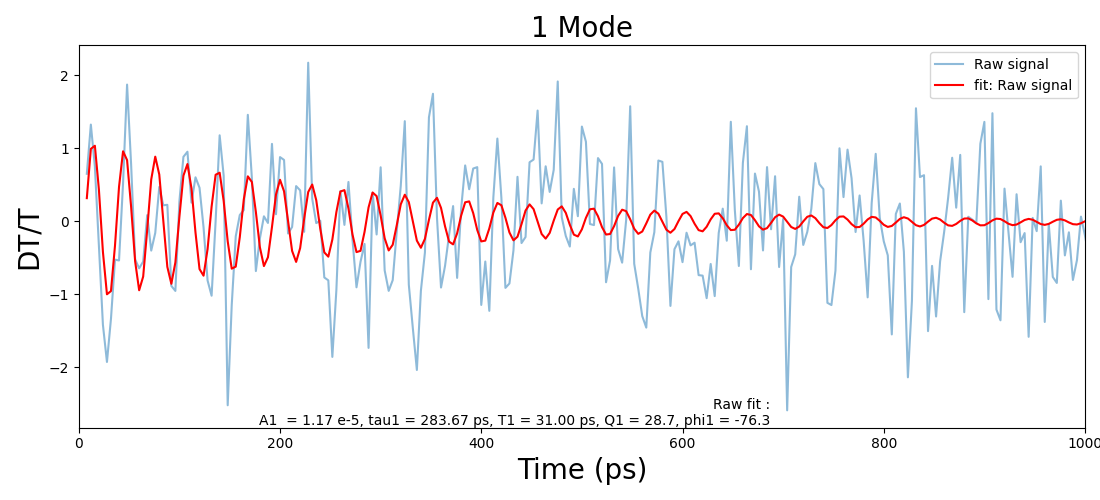

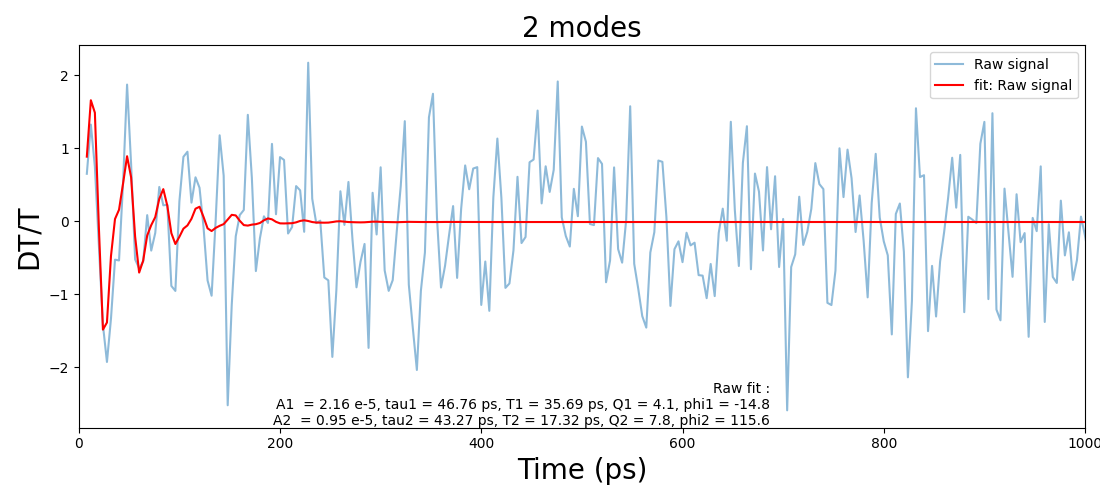

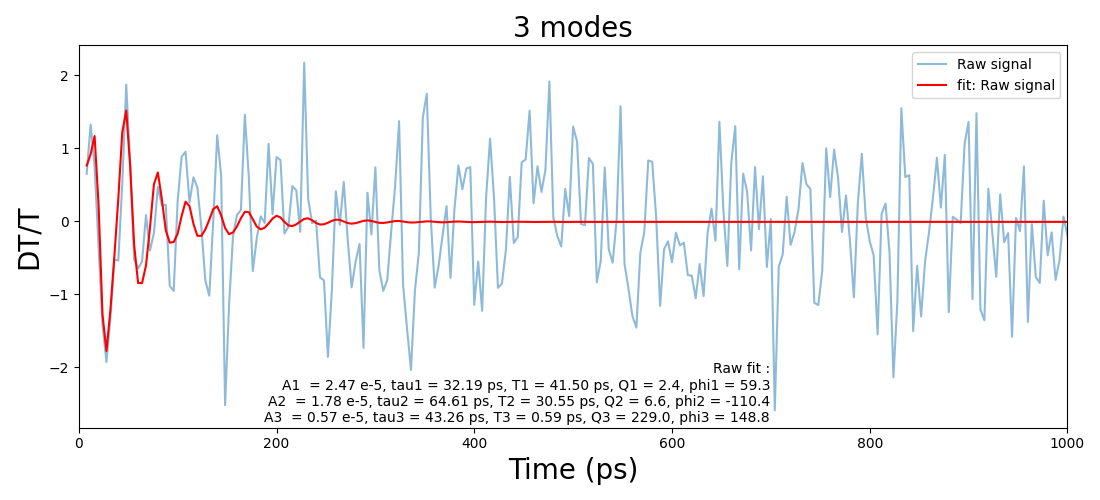

In [36]:
alpha=0.5
offset = 15


fig = plt.figure(figsize = (11,5))
ax = plt.gca()
#Choose which fits to plot
plt.plot(delay, vibrational*1e5, label='Raw signal', alpha=alpha)
plt.plot(delay, Osc1(delay,*popt1)*1e5, 'r-',label='fit: Raw signal')


plt.title(r'1 Mode', fontsize=20)

plt.xlabel('Time (ps)', fontsize=20)
plt.ylabel('DT/T', fontsize=20)



text_raw = 'Raw fit :' + '\n' + 'A1  = {:.2f} e-5, tau1 = {:.2f} ps, T1 = {:.2f} ps, Q1 = {:.1f}, phi1 = {:.1f}'.format(popt1[1]*1e5, popt1[2], popt1[3], np.pi*popt1[2]/popt1[3], popt1[4]*180/np.pi)
plt.text(0.7, 0.15, text_raw, horizontalalignment = 'right', transform=plt.gcf().transFigure)
plt.legend()
plt.tight_layout()


plt.xlim(0, 1000)
fig = plt.figure(figsize = (11,5))
ax = plt.gca()
#Choose which fits to plot
plt.plot(delay, vibrational*1e5, label='Raw signal', alpha=alpha)
plt.plot(delay, Osc2(delay,*popt2)*1e5, 'r-',label='fit: Raw signal')


plt.title(r'2 modes', fontsize=20)

plt.xlabel('Time (ps)', fontsize=20)
plt.ylabel('DT/T', fontsize=20)


text_raw = 'Raw fit :' + '\n' + 'A1  = {:.2f} e-5, tau1 = {:.2f} ps, T1 = {:.2f} ps, Q1 = {:.1f}, phi1 = {:.1f}'.format(popt2[1]*1e5, popt2[2], popt2[3], np.pi*popt2[2]/popt2[3], popt2[4]*180/np.pi) \
                       + '\n' + 'A2  = {:.2f} e-5, tau2 = {:.2f} ps, T2 = {:.2f} ps, Q2 = {:.1f}, phi2 = {:.1f}'.format(popt2[5]*1e5, popt2[6], popt2[7], np.pi*popt2[6]/popt2[7], popt2[8]*180/np.pi)

plt.text(0.7, 0.15, text_raw, horizontalalignment = 'right', transform=plt.gcf().transFigure)
plt.legend()
plt.tight_layout()

plt.xlim(0, 1000)
fig = plt.figure(figsize = (11,5))
ax = plt.gca()
#Choose which fits to plot
plt.plot(delay, vibrational*1e5, label='Raw signal', alpha=alpha)
plt.plot(delay, Osc3(delay,*popt3)*1e5, 'r-',label='fit: Raw signal')






plt.title(r'3 modes', fontsize=20)

plt.xlabel('Time (ps)', fontsize=20)
plt.ylabel('DT/T', fontsize=20)

text_raw = 'Raw fit :' + '\n' + 'A1  = {:.2f} e-5, tau1 = {:.2f} ps, T1 = {:.2f} ps, Q1 = {:.1f}, phi1 = {:.1f}'.format(popt3[1]*1e5, popt3[2], popt3[3], np.pi*popt3[2]/popt3[3], popt3[4]*180/np.pi) \
                       + '\n' + 'A2  = {:.2f} e-5, tau2 = {:.2f} ps, T2 = {:.2f} ps, Q2 = {:.1f}, phi2 = {:.1f}'.format(popt3[5]*1e5, popt3[6], popt3[7], np.pi*popt3[6]/popt3[7], popt3[8]*180/np.pi) \
                       + '\n' + 'A3  = {:.2f} e-5, tau3 = {:.2f} ps, T3 = {:.2f} ps, Q3 = {:.1f}, phi3 = {:.1f}'.format(popt3[9]*1e5, popt3[10], popt3[11], np.pi*popt3[10]/popt3[11], popt3[12]*180/np.pi)
plt.text(0.7, 0.15, text_raw, horizontalalignment = 'right', verticalalignment='bottom', transform=plt.gcf().transFigure)
plt.xlim(0, 1000)
plt.legend()
plt.tight_layout()


### Total fitted signal

In [37]:
# Fit function to use for thermal decay
n_osc_modes = 1
# vibrational_fit = Osc1(delay,*popt1)
# vibrational_fit_noise = Osc1(delay,*popt1_noise)

if n_osc_modes == 1 :
    vibrational_fit = Osc1(delay,*popt1)
    vibrational_fit_noise = Osc1(delay,*popt1_noise)

if n_osc_modes == 2 :
    vibrational_fit = Osc2(delay,*popt2)
    vibrational_fit_noise = Osc2(delay,*popt2_noise)

if n_osc_modes == 3 :
    vibrational_fit = Osc3(delay,*popt3)
    vibrational_fit_noise = Osc3(delay,*popt3_noise)

signal_fitted = vibrational_fit + thermal_fit
signal_fitted_noise = vibrational_fit_noise + thermal_fit_noise

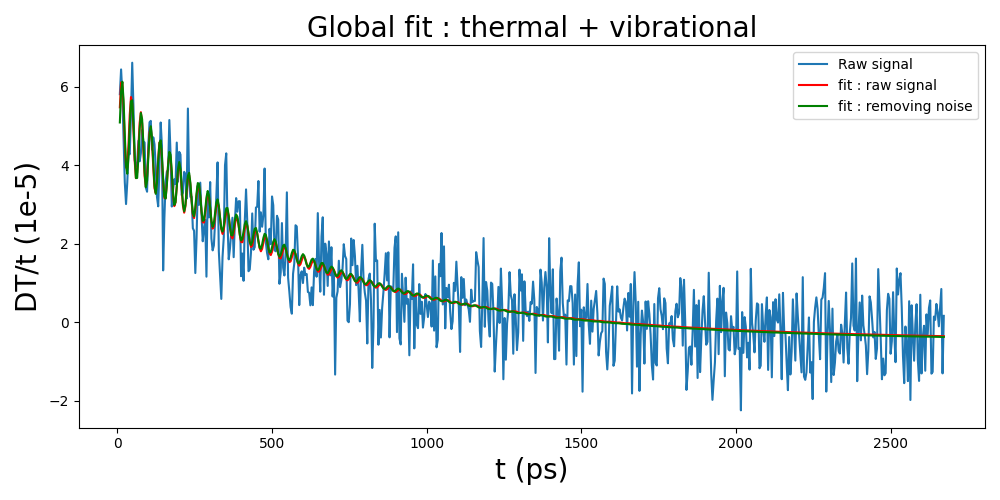

In [38]:
fig = plt.figure(figsize=(10,5))

plt.plot(delay, signal*1e5, label = 'Raw signal')
plt.plot(delay, signal_fitted*1e5, 'r-', label='fit : raw signal')
plt.plot(delay, signal_fitted_noise*1e5,'g-', label = 'fit : removing noise')

plt.title('Global fit : thermal + vibrational', fontsize= 20)
plt.xlabel('t (ps)', fontsize=20)
plt.ylabel('DT/t (1e-5)', fontsize=20)

plt.legend()
plt.tight_layout()

In [39]:
sp_fitted = np.fft.rfft(signal_fitted)
sp_fitted_amp = np.absolute(sp_fitted)
sp_fitted_phase = np.angle(sp_fitted)

sp_fitted_noise = np.fft.rfft(signal_fitted_noise)
sp_fitted_noise_amp = np.absolute(sp_fitted_noise)
sp_fitted_noise_phase = np.angle(sp_fitted_noise)




peaks, peak_dic = find_peaks(sp_fitted_amp, height=0.3e-3, threshold=0.1e-3)
print(peaks)

[]


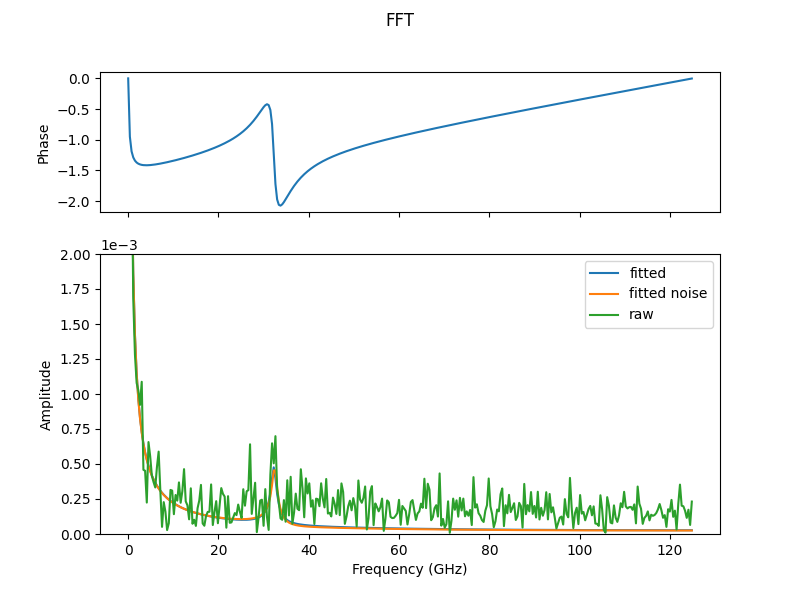

In [40]:
f, (a0, a1) = plt.subplots(2,1, figsize=(8,6), sharex=True,
    gridspec_kw = {'height_ratios':[1, 2]})
a0.plot(freq, sp_fitted_phase)
f.suptitle('FFT')
a0.set_ylabel('Phase')

a1.plot(freq, sp_fitted_amp, label='fitted')
a1.plot(freq, sp_fitted_noise_amp, label='fitted noise')
a1.plot(freq, sp_amp, label='raw')
for i in peaks:
    a1.text(freq[i], sp_fitted_amp[i]+0.02*sp_fitted_amp[0],
            "{0:.2f}".format(1000/freq[i]),horizontalalignment='center',
            verticalalignment='bottom')

a1.set_ylim(0,0.2e-2)
#a1.set_xlim(0,50)
a1.set_xlabel('Frequency (GHz)')
a1.set_ylabel('Amplitude')
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
plt.legend()

## TF fit of oscillations

### Smooth and crop the TF

In [41]:
def prolong(n_prolong, signal, time) :
    """Created a prolongated signal with 0 values in order to have a better resolution on TF signal

    Args:
        n_prolong (int): number of points to add
        signal (1D array): the signal to be prolongated
        delay (1D array): the time axis

    Returns:
        signal_prolongated : prolongtaed signal array
        time_prolongated : prolongated time array
        signal_prolongated_tf : tf of prolongated signal
        freq_prolongated : prolongated frequency
    """

    n_prolong = n_prolong
    dt = time[1] - time[0]

    signal_prolongated = np.concatenate((signal, np.zeros(n_prolong)+signal[-1]*0))
    time_prolongated = np.concatenate((time, np.arange(0, n_prolong)*dt + time[-1] + dt))


    signal_prolongated_tf = np.fft.rfft(signal_prolongated)
    freq_prolongated = 1000*np.fft.rfftfreq(len(time_prolongated), dt)

    return signal_prolongated, time_prolongated, signal_prolongated_tf, freq_prolongated


def crop_signal(f_low, f_high, signal, freq) :
    """Crope the signal to start at f_low and end at f_high

    Args:
        f_low (float): Low frequence to cut
        f_high (float): High frequence to cut
        signal (1D array): array of signal (spectral domain)
        freq (1D array): array of freq

    Returns:
        signal_cut (1D array) : cropped signal
        freq_cut (1D array) : cropped freq 
    """

    idx_low = np.searchsorted(freq, f_low, side='left')
    idx_high = np.searchsorted(freq, f_high, side='left')

    signal_cut = signal[idx_low:idx_high]
    freq_cut = freq[idx_low:idx_high]

    return signal_cut, freq_cut


In [42]:
signal_prolongated, delay_prolongated, signal_prolongated_tf, freq_prolongated = prolong(10000, signal, delay)
signal_prolongated_test, delay_prolongated_test, signal_prolongated_tf_test, freq_prolongated_test = prolong(3000, signal, delay)

#setting the frequencies limite to make an interpolation
f_low = 32
f_high = 42

signal_tf_cropped, freq_cropped = crop_signal(f_low, f_high, signal_prolongated_tf,freq_prolongated)

tf_amp_cropped = np.abs(signal_tf_cropped)



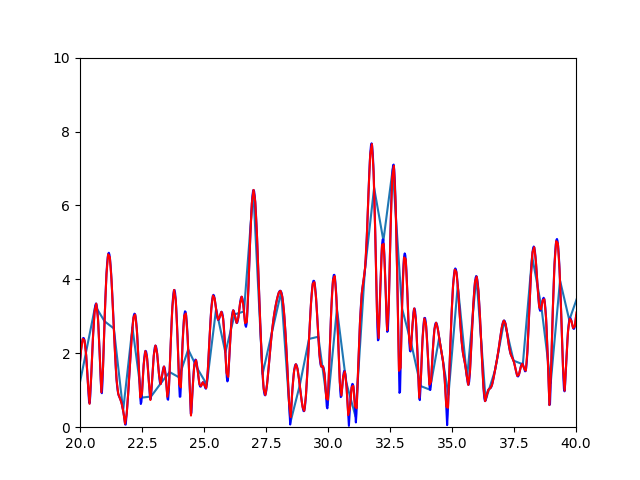

In [43]:
if 1:
    fig = plt.figure()
    plt.plot(freq, np.abs(sp)*1e4)
    plt.plot(freq_prolongated, np.abs(signal_prolongated_tf)*1e4, c='b')
    plt.plot(freq_prolongated_test, np.abs(signal_prolongated_tf_test)*1e4, c='r')
    plt.ylim(0,0.1e-2)
    

    plt.xlim(20, 40)
    plt.ylim(0, 10)

### Lorentzian interpolation

In [44]:
def lorentzienne(f, f0=40, gamma=1, amp=6e-4) :
    A = gamma/(2*np.pi)
    B = 1/(gamma*gamma/4 + (f-f0)*(f-f0))
    return(amp*A*B)

In [45]:
i_peak=0
amp_0 = 0.0006
gamma0 = 0.5
f0 = 36.5

param_ini = [f0, gamma0, amp_0]

coeff, coeff_var = curve_fit(lorentzienne, freq_cropped, tf_amp_cropped, p0 = param_ini)


fig =plt.figure()
plt.plot(freq_cropped, tf_amp_cropped, color='red')
plt.plot(freq_cropped, lorentzienne(freq_cropped, *param_ini), label='initial parameters')
plt.plot(freq_cropped, lorentzienne(freq_cropped, *coeff), label='fit')
plt.legend()

RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 800.